# 02 — Logistic Regression baseline

## Objective

Establish an interpretable multiclass baseline for CICIDS2017, compare conventional random evaluation with chronological evaluation, and test whether a binary detector trained on 2017 transfers to compatible 2018 attack families.

Macro F1 is the primary multiclass metric because every class receives equal weight. For the cross-year binary check, the notebook reports attack-family detection rate and benign false-alarm rate because the stratified 2018 sample does not preserve population class proportions.

In [1]:
import glob, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, classification_report, confusion_matrix

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')
ROOT = './Data/archive'
D17 = f'{ROOT}/CICIDS2017_improved'
SAMPLE18 = './Data/sample_2018_stratified.csv.gz'
RS = 42

def signed_log(a):
    return np.sign(a) * np.log1p(np.abs(a))

/Users/ranga/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/8p/7ywd43m12fz07p58l3312vqh0000gn/T/matplotlib-oqngo7iz because there was an issue with the default path (/Users/ranga/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


## 1. Load and clean CICIDS2017

The baseline uses the same cleaning policy established by the consolidated EDA: attempted attacks are folded into `BENIGN`, leakage-prone identifiers are excluded, infinite rates receive a finite replacement, constants are removed, and exact feature/label duplicates are dropped.

In [2]:
files = sorted(glob.glob(f'{D17}/*.csv'))
if not files:
    raise FileNotFoundError(f'No CSV files found under {D17}')
df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
df['y'] = df['Label'].where(~df['Label'].str.endswith(' - Attempted'), 'BENIGN')
df['attempted'] = df['Label'].str.endswith(' - Attempted')
df['ts'] = pd.to_datetime(df['Timestamp'])

drop = ['id', 'Flow ID', 'Src IP', 'Dst IP', 'Src Port',
        'Timestamp', 'Attempted Category', 'Label']
X = df.drop(columns=drop + ['y', 'attempted', 'ts']).replace([np.inf, -np.inf], np.nan)
FILL_MAX = X.max()
X = X.fillna(FILL_MAX)
constant = [c for c in X if X[c].nunique() <= 1]
X = X.drop(columns=constant)
FEATURES = list(X.columns)

data = X.assign(y=df['y'].values, attempted=df['attempted'].values, ts=df['ts'].values)
before = len(data)
data = data.drop_duplicates(subset=FEATURES + ['y']).reset_index(drop=True)
print(f'Files: {len(files)} | features: {len(FEATURES)} | rows retained: {len(data):,}')
print(f'Duplicates removed: {before-len(data):,} | constants removed: {constant}')
display(data.y.value_counts().rename('flows').to_frame())
del X

Files: 5 | features: 83 | rows retained: 1,841,347
Duplicates removed: 258,629 | constants removed: []


,flows
y,
BENIGN,1434950
DoS Hulk,158468
DDoS,95144
Portscan,90620
Infiltration - Portscan,41179
DoS GoldenEye,7567
FTP-Patator,3972
DoS Slowloris,3859
SSH-Patator,2961


## 2. Random and chronological evaluation splits

In [3]:
LABELS = sorted(data.y.unique(), key=lambda c: (c != 'BENIGN', c))
encoder = LabelEncoder().fit(LABELS)
yall = encoder.transform(data.y)

train_random, test_random = train_test_split(
    data.index.to_numpy(), test_size=0.2, stratify=data.y, random_state=RS
)
rank = data.groupby('y')['ts'].rank(method='first', pct=True)
train_time = data.index[rank <= 0.8].to_numpy()
test_time = data.index[rank > 0.8].to_numpy()
SPLITS = {'random': (train_random, test_random), 'time-ordered': (train_time, test_time)}
for name, (train_idx, test_idx) in SPLITS.items():
    print(f'{name:13s} train {len(train_idx):,} | test {len(test_idx):,}')

Xall = data[FEATURES].astype('float32').to_numpy()

random        train 1,473,077 | test 368,270
time-ordered  train 1,473,071 | test 368,276


## 3. Fit and evaluate the multiclass baseline

The signed `log1p` transformation reduces extreme skew while preserving negative anomaly values. Standardization is required because Logistic Regression is scale-sensitive. Balanced class weights prevent the benign majority from dominating optimization.

In [4]:
rows, predictions, fitted, timing = [], {}, {}, []
for split_name, (train_idx, test_idx) in SPLITS.items():
    model = make_pipeline(
        FunctionTransformer(signed_log), StandardScaler(),
        LogisticRegression(max_iter=500, class_weight='balanced', random_state=RS)
    )
    started = time.perf_counter(); model.fit(Xall[train_idx], yall[train_idx])
    fit_seconds = time.perf_counter() - started
    started = time.perf_counter(); predicted = model.predict(Xall[test_idx])
    predict_seconds = time.perf_counter() - started
    precision, recall, f1, support = precision_recall_fscore_support(
        yall[test_idx], predicted, labels=encoder.transform(LABELS), zero_division=0)
    rows.append(pd.DataFrame({'split': split_name, 'model': 'Logistic Regression baseline',
        'class': LABELS, 'precision': precision, 'recall': recall, 'f1': f1, 'support': support}))
    predictions[split_name] = predicted
    fitted[split_name] = model
    timing.append({'split': split_name, 'fit_seconds': fit_seconds,
                   'predict_seconds': predict_seconds})
    print(f'{split_name:13s} macro F1 {f1.mean():.4f} | fit {fit_seconds:.1f}s')

per_class = pd.concat(rows, ignore_index=True)
def summarize(group):
    return pd.Series({'macro_precision': group.precision.mean(),
                      'macro_recall': group.recall.mean(),
                      'macro_f1': group.f1.mean(),
                      'weighted_f1': np.average(group.f1, weights=group.support),
                      'attack_macro_f1': group.loc[group['class'] != 'BENIGN', 'f1'].mean()})
summary = per_class.groupby(['split', 'model']).apply(summarize, include_groups=False).reset_index()
per_class.to_csv('02_logistic_baseline_per_class.csv', index=False)
summary.to_csv('02_logistic_baseline_summary.csv', index=False)
pd.DataFrame(timing).to_csv('02_logistic_baseline_timing.csv', index=False)
display(summary.round(4))

random        macro F1 0.8241 | fit 488.7s


time-ordered  macro F1 0.7278 | fit 187.5s


,split,model,macro_precision,macro_recall,macro_f1,weighted_f1,attack_macro_f1
0,random,Logistic Regression baseline,0.7919,0.9779,0.8241,0.9898,0.8126
1,time-ordered,Logistic Regression baseline,0.6868,0.9457,0.7278,0.9841,0.7101


## 4. Overall and per-class comparison

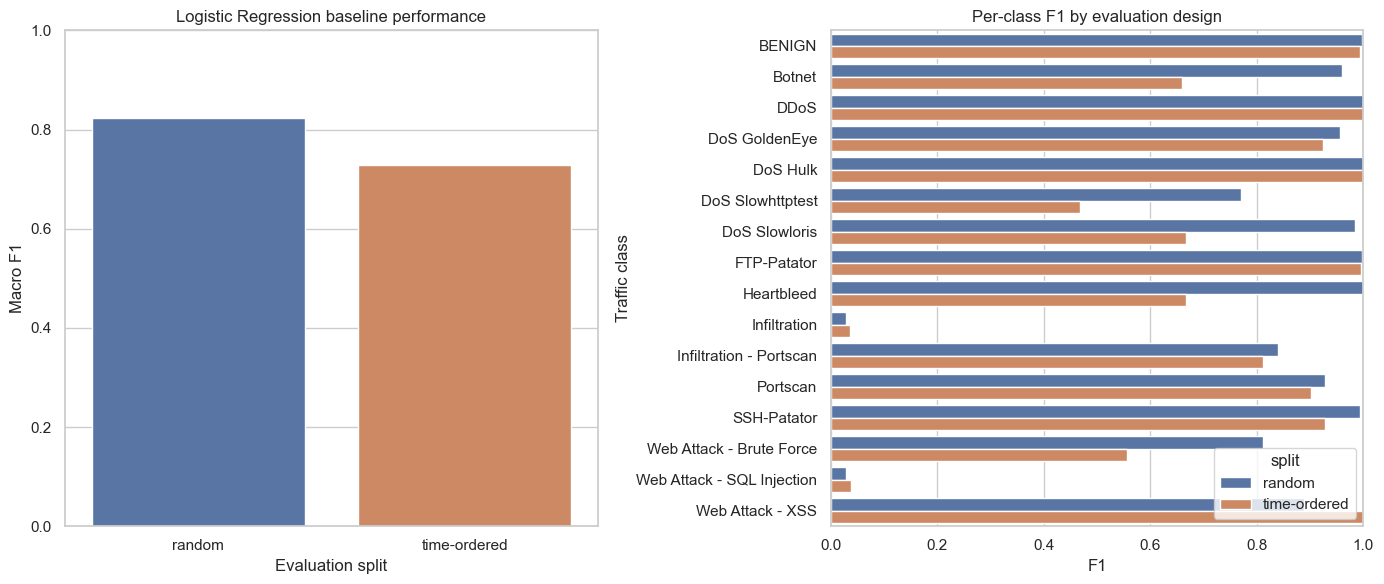

split,class,random,time-ordered
0,BENIGN,0.9968,0.9937
1,Botnet,0.9608,0.6592
2,DDoS,0.9997,0.9990
3,DoS GoldenEye,0.9560,0.9237
4,DoS Hulk,0.9991,0.9986
5,DoS Slowhttptest,0.7711,0.4686
6,DoS Slowloris,0.9847,0.6672
7,FTP-Patator,0.9981,0.9956
8,Heartbleed,1.0000,0.6667
9,Infiltration,0.0285,0.0361


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=summary, x='split', y='macro_f1', hue='split', legend=False, ax=axes[0])
axes[0].set_ylim(0, 1); axes[0].set_xlabel('Evaluation split'); axes[0].set_ylabel('Macro F1')
axes[0].set_title('Logistic Regression baseline performance')

plot_class = per_class.pivot(index='class', columns='split', values='f1').reset_index()
plot_long = plot_class.melt(id_vars='class', var_name='split', value_name='f1')
sns.barplot(data=plot_long, y='class', x='f1', hue='split', ax=axes[1])
axes[1].set_xlim(0, 1); axes[1].set_xlabel('F1'); axes[1].set_ylabel('Traffic class')
axes[1].set_title('Per-class F1 by evaluation design')
plt.tight_layout(); plt.show()
display(plot_class.round(4))

## 5. Time-ordered confusion matrix

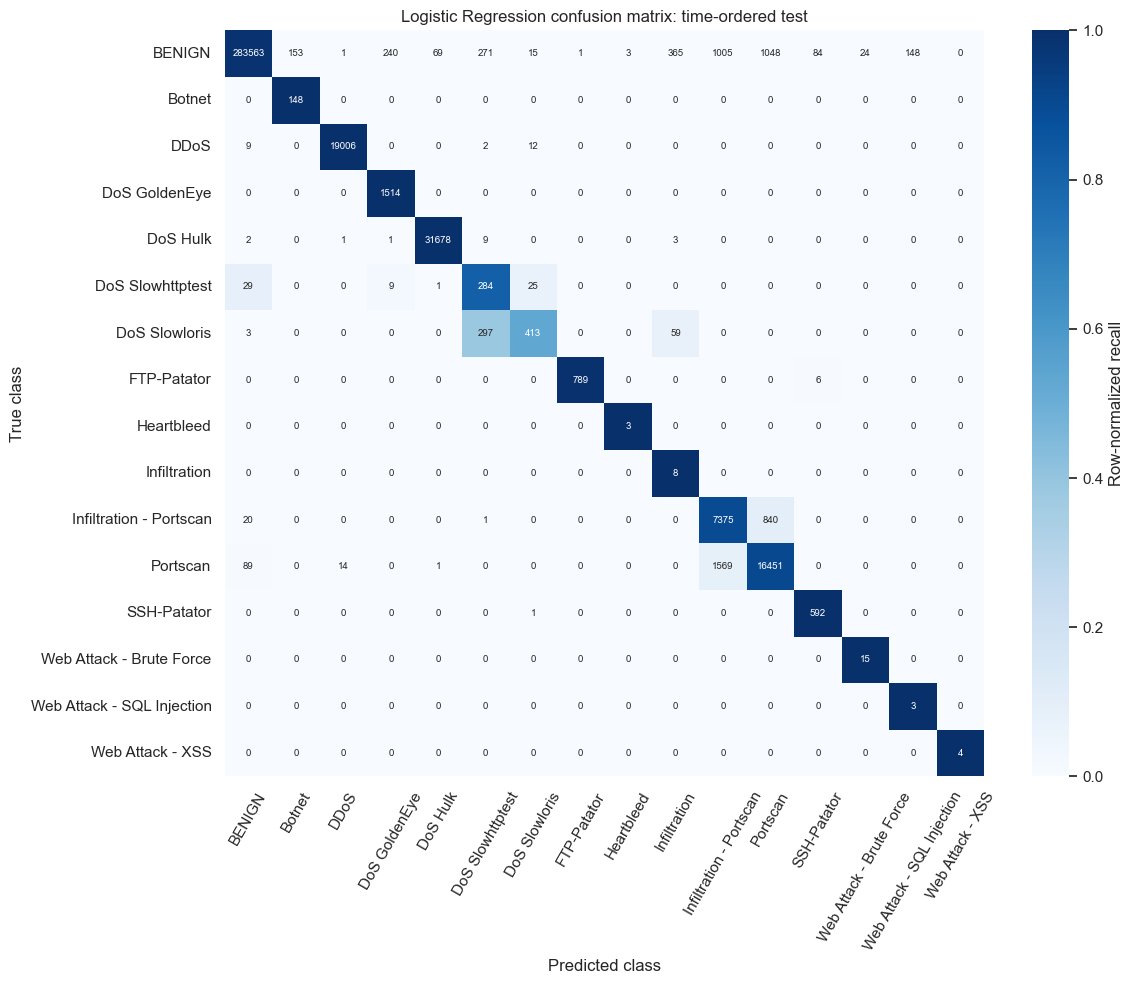

                            precision    recall  f1-score   support

                    BENIGN     0.9995    0.9881    0.9937    286990
                    Botnet     0.4917    1.0000    0.6592       148
                      DDoS     0.9992    0.9988    0.9990     19029
             DoS GoldenEye     0.8583    1.0000    0.9237      1514
                  DoS Hulk     0.9978    0.9995    0.9986     31694
          DoS Slowhttptest     0.3287    0.8161    0.4686       348
             DoS Slowloris     0.8863    0.5350    0.6672       772
               FTP-Patator     0.9987    0.9925    0.9956       795
                Heartbleed     0.5000    1.0000    0.6667         3
              Infiltration     0.0184    1.0000    0.0361         8
   Infiltration - Portscan     0.7413    0.8955    0.8111      8236
                  Portscan     0.8971    0.9077    0.9023     18124
               SSH-Patator     0.8680    0.9983    0.9286       593
  Web Attack - Brute Force     0.3846    1.0000

In [6]:
predicted = predictions['time-ordered']
matrix = confusion_matrix(yall[test_time], predicted, labels=encoder.transform(LABELS))
normalized = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(normalized, annot=matrix, fmt='d', cmap='Blues', vmin=0, vmax=1,
            xticklabels=LABELS, yticklabels=LABELS, annot_kws={'fontsize': 7},
            cbar_kws={'label': 'Row-normalized recall'}, ax=ax)
ax.set_xlabel('Predicted class'); ax.set_ylabel('True class')
ax.set_title('Logistic Regression confusion matrix: time-ordered test')
ax.tick_params(axis='x', labelrotation=60); ax.tick_params(axis='y', labelrotation=0)
plt.tight_layout(); plt.show()
print(classification_report(yall[test_time], predicted,
      labels=encoder.transform(LABELS), target_names=LABELS, digits=4, zero_division=0))

## 6. Interpretable coefficients

Because correlated features divide and destabilize coefficients, these values identify associations rather than causal drivers. The chart reports the strongest absolute standardized coefficients for the chronological model.

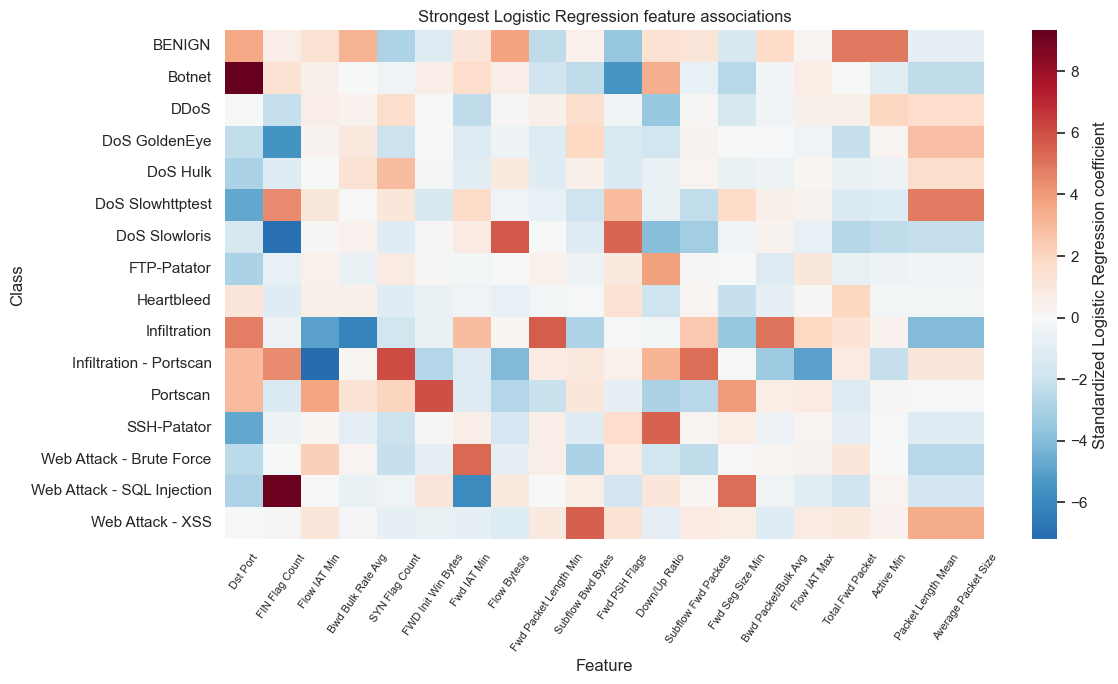

In [7]:
lr = fitted['time-ordered'].named_steps['logisticregression']
coef = pd.DataFrame(lr.coef_, index=encoder.classes_, columns=FEATURES)
top = coef.abs().max().nlargest(20).index
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(coef[top], center=0, cmap='RdBu_r', ax=ax,
            cbar_kws={'label': 'Standardized Logistic Regression coefficient'})
ax.set_title('Strongest Logistic Regression feature associations')
ax.set_xlabel('Feature'); ax.set_ylabel('Class')
ax.tick_params(axis='x', rotation=55, labelsize=8)
plt.tight_layout(); plt.show()

## 7. Cross-year binary generalization check

The cross-year section moved here from the extended EDA because it fits and evaluates a model. The chronological 2017 training period supplies all effective attack rows and a bounded 400,000-row benign sample. The binary Logistic Regression detector is evaluated on the 2017 chronological test period and on the stratified 2018 sample.

Overall accuracy on the capped 2018 sample is not meaningful. The relevant measures are detection rate for each compatible attack family, false-alarm rate on genuine benign traffic, and alarm rate on attempted attacks that the baseline labels benign.

In [8]:
if not os.path.exists(SAMPLE18):
    raise FileNotFoundError('Run 01_eda.ipynb first to create the cached 2018 sample.')
s18 = pd.read_csv(SAMPLE18)
s18['attempted'] = s18.Label.str.endswith(' - Attempted')
X18 = s18[FEATURES].replace([np.inf, -np.inf], np.nan).fillna(FILL_MAX)
s18[FEATURES] = X18

MAP18 = {'BENIGN': 'BENIGN', 'SSH-BruteForce': 'SSH-Patator', 'DoS Hulk': 'DoS Hulk',
         'DoS GoldenEye': 'DoS GoldenEye', 'DoS Slowloris': 'DoS Slowloris',
         'DDoS-LOIC-HTTP': 'DDoS', 'Botnet Ares': 'Botnet',
         'Infiltration - NMAP Portscan': 'Infiltration - Portscan',
         'Web Attack - Brute Force': 'Web Attack - Brute Force',
         'Web Attack - XSS': 'Web Attack - XSS', 'Web Attack - SQL': 'Web Attack - SQL Injection',
         'Infiltration - Communication Victim Attacker': 'Infiltration'}
s18['family'] = s18.Label.map(MAP18)
shared = [f for f in MAP18.values() if (s18.family == f).sum() >= 30 and (data.y == f).sum() >= 30]

ben_idx = train_time[yall[train_time] == encoder.transform(['BENIGN'])[0]]
att_idx = train_time[yall[train_time] != encoder.transform(['BENIGN'])[0]]
rng = np.random.default_rng(RS)
fit_idx = np.r_[rng.choice(ben_idx, min(400_000, len(ben_idx)), replace=False), att_idx]
binary = make_pipeline(FunctionTransformer(signed_log), StandardScaler(),
                       LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RS))
started = time.perf_counter()
binary.fit(Xall[fit_idx], (data.y.iloc[fit_idx].values != 'BENIGN').astype(int))
print(f'Binary baseline fit: {time.perf_counter()-started:.1f}s on {len(fit_idx):,} flows')

test17 = data.iloc[test_time][FEATURES + ['y', 'attempted']].copy()
test17['eval_group'] = np.where(test17.attempted, 'Attempted (scored as benign)', test17.y)
s18['eval_group'] = np.where(s18.attempted, 'Attempted (scored as benign)', s18.family)

def alarm_rates(frame, group_column):
    predicted = binary.predict(frame[FEATURES])
    return pd.Series(predicted).groupby(frame[group_column].values).mean()

cross_year = pd.DataFrame({
    '2017 time-test': alarm_rates(test17, 'eval_group'),
    '2018 sample': alarm_rates(s18.dropna(subset=['eval_group']), 'eval_group'),
}).reindex(['BENIGN', 'Attempted (scored as benign)'] + [f for f in shared if f != 'BENIGN'])
cross_year.index = ['BENIGN false-alarm rate' if x == 'BENIGN' else
                    'Attempted alarm rate' if x.startswith('Attempted') else f'{x} detection rate'
                    for x in cross_year.index]
cross_year.to_csv('02_logistic_cross_year_detection.csv')
display(cross_year.round(4))

Binary baseline fit: 12.2s on 725,111 flows


,2017 time-test,2018 sample
BENIGN false-alarm rate,0.0054,0.0326
Attempted alarm rate,0.8365,0.8890
SSH-Patator detection rate,0.9798,0.3471
DoS Hulk detection rate,0.9993,0.0224
DoS GoldenEye detection rate,0.9604,0.5838
DoS Slowloris detection rate,0.9832,0.9975
DDoS detection rate,1.0000,1.0000
Botnet detection rate,0.0000,0.0001
Infiltration - Portscan detection rate,0.9805,0.8362
Web Attack - Brute Force detection rate,0.0000,0.0000


## 8. Cross-year visualization

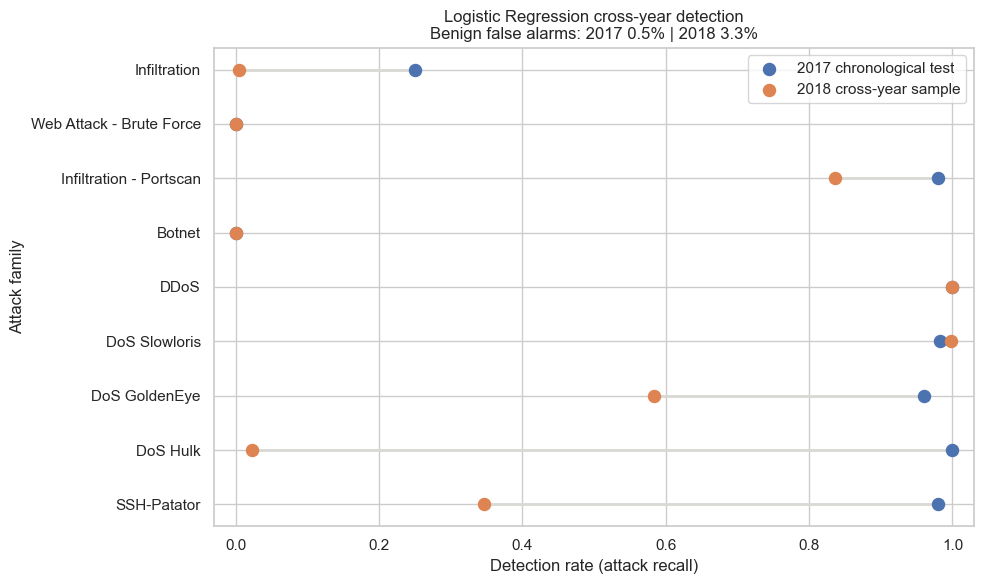

In [9]:
families = [f for f in shared if f != 'BENIGN']
rows = [f'{f} detection rate' for f in families]
fig, ax = plt.subplots(figsize=(10, 6))
yy = np.arange(len(families))
a = cross_year.loc[rows, '2017 time-test'].values
b = cross_year.loc[rows, '2018 sample'].values
ax.hlines(yy, np.minimum(a, b), np.maximum(a, b), color='#d9d8d4', lw=2)
ax.scatter(a, yy, s=75, color='#4C72B0', label='2017 chronological test', zorder=3)
ax.scatter(b, yy, s=75, color='#DD8452', label='2018 cross-year sample', zorder=3)
ax.set_yticks(yy); ax.set_yticklabels(families); ax.set_xlim(-0.03, 1.03)
ax.set_xlabel('Detection rate (attack recall)'); ax.set_ylabel('Attack family')
fa17 = cross_year.loc['BENIGN false-alarm rate', '2017 time-test']
fa18 = cross_year.loc['BENIGN false-alarm rate', '2018 sample']
ax.set_title(f'Logistic Regression cross-year detection\nBenign false alarms: 2017 {fa17:.1%} | 2018 {fa18:.1%}')
ax.legend(); plt.tight_layout(); plt.show()

## 9. Baseline interpretation

The Logistic Regression baseline achieved **0.8241 macro F1** on the random split and **0.7278** on the chronological split. The 0.0963 decline shows that a conventional random evaluation overstates performance on later traffic. The chronological score is the appropriate baseline for comparing subsequent models.

Cross-year behavior was substantially weaker for several families. DoS Hulk detection fell from **99.9% to 2.2%**, SSH brute force from **98.0% to 34.7%**, and Infiltration from **25.0% to 0.5%**. Slowloris and DDoS remained detectable, while the internal port scan retained 83.6% detection. The benign false-alarm rate rose from **0.5% in 2017 to 3.3% in 2018**.

Logistic Regression therefore provides an interpretable minimum benchmark, but its within-year performance should not be interpreted as expected production performance. Later models should be compared primarily on chronological macro F1 and should also be checked for cross-year family recall and false alarms.
